# Lab 2: Tutorial solutions — handwritten-digit recognition
**Contemporary Machine Learning in Theory and Practice · WS26/27**

**Tutorial: 5 November 2026. Student reference notebook.**

This notebook contains worked solutions to **Exercises 1, 2, 3, 4, and 6**.
Exercises 5 and 7 are homework and their solutions are not included.
The original exercise numbers are retained.

The model follows the guided version. It is also one valid choice for the
independent version; other architectures and implementations can be correct.
Use the explanations to understand the code, then return to your own exercise
notebook. No AI tool is needed to use this reference.

Run the code cells from top to bottom with **Shift+Enter**. This notebook builds
and trains its own model: it does not depend on having run another notebook.
Saved outputs illustrate one CPU run; your predictions and numerical results
may differ across software versions and devices. The optional drawing pad
requires a live session and is disabled by default.


## Setup and how to read this notebook

Keep `lab_02_support.py` beside this notebook when using local Jupyter or MIN.
Use the existing course environment; the first dataset download needs internet.
For a missing package, see the repair instructions below.

**Google Colab: upload the helper file.** Download `lab_02_support.py` from the
course materials without renaming it. Add a code cell before the import cell,
paste the following code, and run it **only in Colab**:

```python
from google.colab import files
uploaded = files.upload()
```

Click **Choose files**, select `lab_02_support.py`, wait for the upload to finish,
then run the import cell. Opening the notebook does not upload this helper
automatically. Upload it again when a new runtime starts; saving the notebook
to Google Drive does not also save files uploaded to the temporary runtime.

**Package check and installation.** On **MIN or Colab**, try the import cell first.
If `torchvision` or the drawing widget fails on MIN, follow the targeted repair
steps below. Keep the existing PyTorch installation. In Colab, use its existing
PyTorch/torchvision pair and the optional-widget instructions below.
On **Nix**, update the course files and re-enter `nix develop` from the course root;
the provided environment remains CPU-only.

For **local Python**, activate your existing course environment. Run these commands
in its terminal from the **student repository root**, not in a notebook code cell:

```bash
python -m pip install "torch>=2.2,<3" "torchvision>=0.17,<1" --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r lab_02/requirements.txt
```

On **macOS**, omit `--index-url https://download.pytorch.org/whl/cpu` from the first
command. The requirements include `Pillow>=9.1` and Matplotlib. On Windows, use the
course environment's Python executable as shown in `setup/local.md`. Restart your
notebook kernel after installation. Use a compatible PyTorch/torchvision pair;
a `torchvision` import error can indicate incompatible versions.

**Optional drawing pad.** Exercise 6 includes a mouse/touch drawing pad with
the extra package `anywidget` (listed in `requirements-drawing.txt`). The cell
checks this only when you try the pad; it is not needed for the core lab.
Supplied digit images and loading your own PNG/JPEG are available alternatives.

| Project step | Pay attention to | Reference to consult when needed |
|---|---|---|
| Read an image | A batch has shape `(B, C, H, W)`; for MNIST `C=1` | [Tensor basics](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) |
| Compose layers | Each layer's output must fit the next layer's input | [Build a network: `Flatten`, `Linear`, `ReLU`, `Sequential`](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) |
| Apply a filter | `in_channels`, `out_channels`, `kernel_size`, `padding` | [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) |
| Reduce spatial size | Pool each channel separately | [`nn.MaxPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) |
| Predict and measure error | Largest score; labels are integers, not ten-entry vectors | [`argmax`](https://docs.pytorch.org/docs/stable/generated/torch.argmax.html), [`CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) |
| Evaluate a model | Evaluation mode and calculations without gradients | [`Module.eval`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval), [`no_grad`](https://docs.pytorch.org/docs/stable/generated/torch.no_grad.html) |

**Understand now:** images, layer composition, shapes, class scores, loss,
validation, and your experimental choices. **Supplied for use:** downloading,
batching, device transfers in the trainer, automatic differentiation, and
parameter updates. Lab 3 will explain the training machinery in detail.
You can read the documented functions in `lab_02_support.py` whenever useful.


### If a library or the drawing pad does not load

**1. Missing `lab_02_support`.** Keep `lab_02_support.py` in the same folder as this notebook. In Colab, upload it again after a new runtime starts.

**2. Missing or incompatible `torchvision` on MIN.** First run this in a new notebook cell, before the lab's import cell:

```python
import sys
import torch
print(sys.executable)
print(torch.__version__)
```

If PyTorch reports **`2.12.0+cu130`**, use the following command in a separate notebook cell. This is the repair that worked in the instructor's MIN environment:

```python
%pip install --no-deps torchvision==0.27.0 --index-url https://download.pytorch.org/whl/cu130
```

`--no-deps` leaves the existing PyTorch installation in place. Save the notebook, choose **Kernel → Restart Kernel**, and rerun the lab's import cell. If both libraries import successfully, continue with the lab. If your PyTorch version is different, or this repair fails, send the printed version and full error to the tutor so the matching torchvision build can be selected. Use the local setup instructions for local Python; on Nix, update the course files and re-enter `nix develop`.

**3. Missing `anywidget` or `Failed to load model class 'AnyModel' from module 'anywidget'`.** On **MIN, local Python, or Colab**, install the optional drawing package in a new notebook cell:

```python
%pip install "anywidget>=0.9.18,<1"
```

On **MIN**, save all open notebooks, then use **File → Hub Control Panel → Stop My Server → Start My Server**. Reopen JupyterLab and hard-refresh the browser page (`Ctrl+Shift+R`, or `Cmd+Shift+R` on macOS). Restarting only the kernel may not load the newly installed browser extension.

With **local JupyterLab**, stop and relaunch the full JupyterLab server from your course environment, then refresh the browser. In **Colab**, restart the session and rerun the supplied drawing cell, which enables the custom widget manager. On **Nix**, use the supplied environment instead of pip.

A restart clears the trained model from memory: rerun your completed setup, model, and training cells before trying the drawing pad. If the canvas still fails after these steps, send the error to the tutor and use Exercise 6's PNG/JPEG option. The rest of the lab does not need the widget.

Only run a repair when the corresponding import or widget fails. More help and official references are in the course file `setup/troubleshooting.md`.


In [1]:
# Supplied: imports and device selection.
from pathlib import Path
import torch
import torchvision
import PIL
import matplotlib
from torch import nn
import matplotlib.pyplot as plt
from lab_02_support import (
    make_loaders, train_model, evaluate_model, predict_images,
    plot_history, show_images, count_parameters, load_digit, make_example_digits,
)

SEED = 2026
EPOCHS = 3
LEARNING_RATE = 0.001
BATCH_SIZE = 128
# Keep the CPU workload modest, including on shared university servers.
torch.set_num_threads(min(2, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__, "| Matplotlib:", matplotlib.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
else:
    print("CPU is sufficient for the small project; training may take longer.")


PyTorch: 2.15.0+cpu | torchvision: 0.29.2+cpu
Pillow: 13.0.0 | Matplotlib: 3.10.8
Device: cpu
CPU is sufficient for the small project; training may take longer.


## Supplied data: three distinct roles

We use a fixed random subset of **10,000 training images** and a disjoint subset
of **2,000 validation images** from MNIST's official training split. The other
images in that split are unused in this lab. MNIST's **10,000 official test images**
remain separate.

- **Training data:** used to change the network parameters.
- **Validation data:** used here to inspect the first model on images not used for parameter updates.
- **Test data:** reserved for homework; no test predictions or test evaluation are made here.

A data loader supplies one batch `(images, labels)` at a time. Images are floating-point
tensors in `[0, 1]`; labels are integers from 0 to 9. The first batch has at most
128 images. The last batch can be smaller. The plotting and model code do not
require you to learn NumPy.


In [2]:
# Supplied: load the fixed split. The test loader is created but never evaluated here.
train_loader, val_loader, test_loader = make_loaders(
    root="data", batch_size=BATCH_SIZE,
    train_size=10000, val_size=2000, seed=SEED,
)
images, labels = next(iter(train_loader))
print("Training / validation / test sizes:",
      len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print("Batch shapes:", images.shape, labels.shape)


Training / validation / test sizes: 10000 2000 10000
Batch shapes: torch.Size([128, 1, 28, 28]) torch.Size([128])


## 1. Explore the digit images · Tutorial, 10 minutes

**(a)** Write code that displays at least eight images with their labels, prints the image and label tensor shapes, and reports the minimum and maximum pixel values. Explain every dimension and what a pixel value near zero means.

**(b)** Choose one digit. Make an independent copy and erase a small rectangular patch. Before running your code, state whether you expect the digit to remain recognisable. Display the original and modified image side by side and record your chosen index and patch. Do not alter the training data.

**Useful tools:** tensor indexing, `.shape`, `.min()`, `.max()`, `.item()`, `.clone()`, and `torch.stack`. The supplied `show_images` function takes a batch and optional `labels` and `predictions`.


**Hints.** `images[0]` has shape `(1, 28, 28)`, whereas `images[0, 0]` is its grayscale matrix. You can call `show_images(images, labels=labels, max_images=8)` to display a batch. For a tensor called `picture`, `picture[:, 4:8, 12:16] = 0` erases a rectangle. `torch.stack([first, second])` adds a batch dimension to two individual images. The solution below combines these operations.


**Reading the code.** A tensor is an array with several indices.
`images.shape` lists the sizes of its dimensions. `.min()` and `.max()` return
single-value tensors; `.item()` converts each to an ordinary Python number.
`images[:8]` means the first eight images (indices 0 through 7), and
`labels[:8]` selects their matching labels. The supplied plotting helper
handles the layout; it does not train or evaluate a model.


Image / label shapes: torch.Size([128, 1, 28, 28]) torch.Size([128])
Pixel range: 0.0 1.0


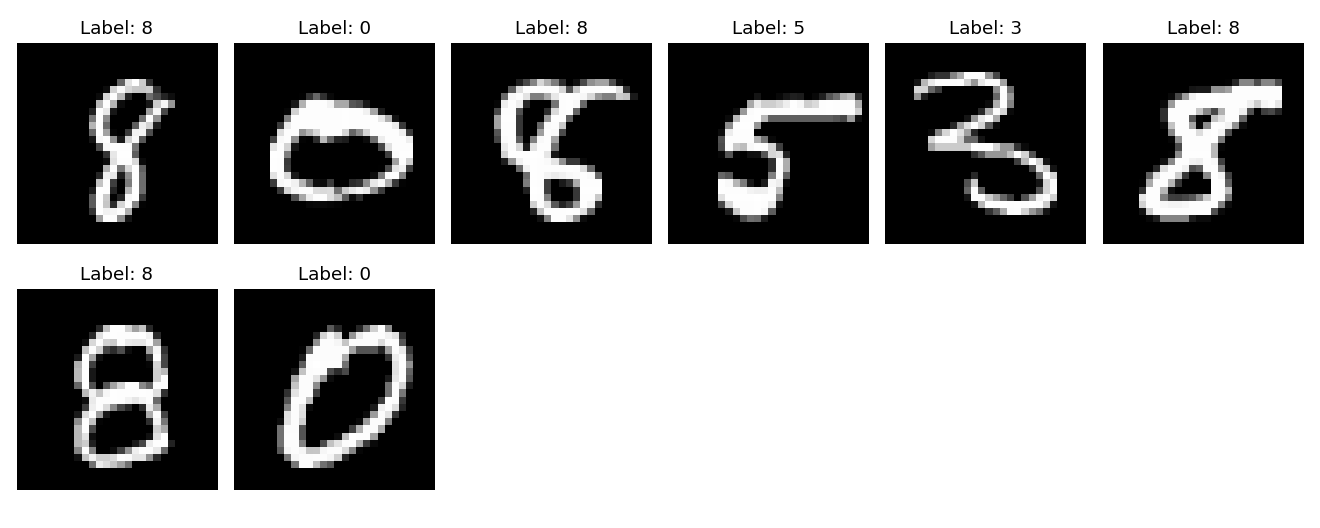

In [3]:
print("Image / label shapes:", images.shape, labels.shape)
print("Pixel range:", images.min().item(), images.max().item())
show_images(images[:8], labels=labels[:8], max_images=8)


**Example expectation before changing the image.** Removing a central patch
may leave enough surrounding strokes to recognise the digit, but it could
erase the feature that distinguishes it from another digit.

`images[0]` selects the first image. `.clone()` makes an independent copy;
writing to that copy leaves the original intact. In `[:, 10:16, 10:16]`, the
colon selects the channel and the two slices select rows and columns 10 through
15. `torch.stack([original, changed])` puts two images into a new batch.


Changed patch: rows 10:16, columns 10:16


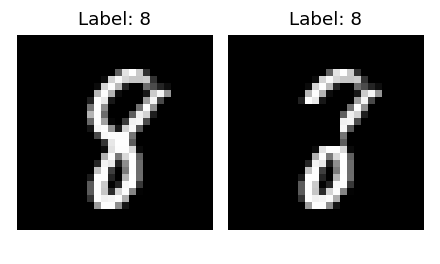

In [4]:
digit_index = 0
original = images[digit_index]
changed = original.clone()
changed[:, 10:16, 10:16] = 0.0
show_images(torch.stack([original, changed]),
            labels=labels[digit_index].repeat(2), max_images=2)
print("Changed patch: rows 10:16, columns 10:16")


**Reference answer.**

A batch has shape `(B, 1, 28, 28)`: number of images, grayscale channel, height, and width. Labels have shape `(B,)` and are integers from 0 to 9. Zero is black and one is white; intermediate values are shades of gray. We clone before writing so that the original stays unchanged.

This example removes the central 6-by-6 patch of the first image. The surrounding strokes may preserve the identity, but the effect depends on the selected image; compare the two displayed images and record whether the remaining strokes are sufficient for a human reader.


**Observation in the saved run.** The chosen image is an 8. Erasing the patch
breaks the connection between its upper and lower parts. The remaining loops
still suggest an 8 to a human reader, but the damaged image is more ambiguous.
The original on the left is unchanged.


### Extra help: display one image without the plotting helper

`images[i, 0]` selects image `i` and its grayscale channel, giving a 28-by-28
matrix. `.cpu()` makes the tensor available to Matplotlib if it was on a GPU.
The fixed colour range below means zero is black and one is white.


Fourth training-subset item: torch.Size([1, 28, 28]) label: 3


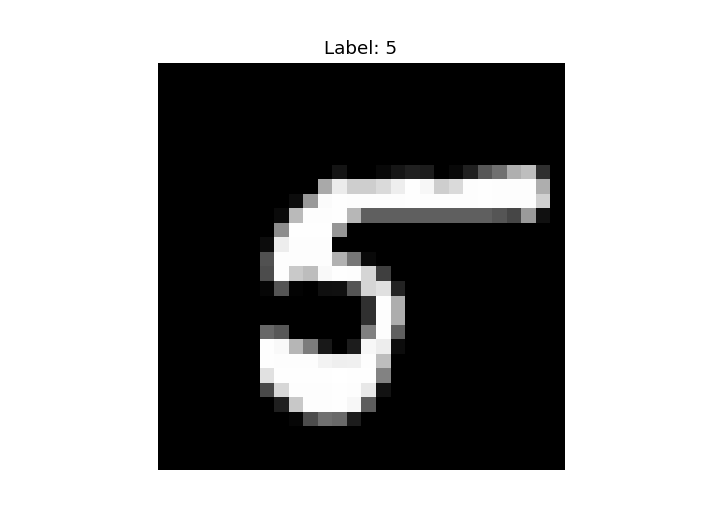

In [5]:
i = 3  # Fourth image of the current batch; indices start at zero.
plt.imshow(images[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
plt.title(f"Label: {labels[i].item()}")
plt.axis("off")
plt.show()
plt.close()

# To access a dataset item rather than the current batch:
dataset_image, dataset_label = train_loader.dataset[3]
print("Fourth training-subset item:", dataset_image.shape, "label:", dataset_label)
# This need not be images[3], because the training loader shuffles the data.


## 2. Construct a CNN · Tutorial, 25 minutes

A layer is a function on tensors. `nn.Sequential(layer1, layer2, ...)` composes
these functions in the listed order. For example, `nn.Linear(3, 2)` maps three
features to two scores for each item in a batch. It includes a learned bias.


In [6]:
# Supplied small example: first predict the output shape.
tiny_network = nn.Sequential(nn.Linear(3, 2), nn.ReLU())
tiny_input = torch.tensor([[1., 0., -1.], [2., 1., 0.]])
print("Tiny input/output:", tiny_input.shape, tiny_network(tiny_input).shape)

# One convolution: 1 input channel, 4 output channels, a 3-by-3 filter.
# Padding adds a one-pixel border so this stride-one layer keeps H and W.
example_conv = nn.Conv2d(1, 4, kernel_size=3, padding=1)
print("Convolution output:", example_conv(images[:2]).shape)


Tiny input/output: torch.Size([2, 3]) torch.Size([2, 2])
Convolution output: torch.Size([2, 4, 28, 28])


**Useful tools.**

- `nn.Conv2d(c_in, c_out, kernel_size=3, padding=1)` uses `c_out` learned filters,
  each spanning all `c_in` input channels. Here the stride is one.
- `nn.ReLU()` applies the positive part to every entry.
- `nn.MaxPool2d(2)` takes a maximum over each nonoverlapping $2\times2$ block;
  on our even image sizes it halves both spatial dimensions.
- `nn.Flatten()` keeps the batch dimension and combines all remaining dimensions.
- `nn.Linear(number_of_features, 10)` produces ten **raw class scores** per image.

A convolution with biases has
$$
c_{\mathrm{out}}\bigl(c_{\mathrm{in}} k^2+1\bigr)
$$
trainable parameters for a square filter of width $k$. A linear layer with
$d$ inputs and $m$ outputs has $m(d+1)$ parameters.


**(a)** Write the complete function `make_model()` returning a new `nn.Sequential` network. Translate this architecture from words to code:

1. A convolution from the grayscale input to eight channels, followed by ReLU and max pooling over nonoverlapping 2-by-2 blocks.
2. A convolution from those eight channels to sixteen channels, followed by ReLU and the same pooling operation.
3. Flatten the feature maps and apply an affine layer producing ten raw class scores.

Both convolutions use 3-by-3 filters, stride one, padding one, and biases. The affine layer also has a bias. Do not put ReLU or softmax after the final scores. Use the short examples and layer reference above, but write the complete layer sequence yourself.

**Before running:** list the tensor shape after every layer. Then write a short loop applying the layers one at a time to `images[:2]`, printing the intermediate shapes to check your calculations. A sequential network can be iterated over with `for layer in model:`.

**(b)** Calculate the parameter count of **each trainable layer** by hand, add the counts, and check the total with `count_parameters(model)`. Explain why the convolutional parameter counts do not depend on the image height and width. Identify which layer has the most parameters.

Keep a table of layer names, output shapes, and parameter counts in your answer. The flattening head used in the guided architecture differs from Lecture 2's global-average-pooling head; both are possible design choices.


**Reading the model definition.** `def make_model():` defines a function;
its indented lines are its body. `return` sends the constructed network back
to the caller. Each call to `make_model()` creates a new network with new
parameters. `nn.Sequential` applies the listed layers in order, so the output
of each layer must have the shape expected by the next one.

Here pooling changes 28-by-28 images into 14-by-14 and then 7-by-7 feature
maps. There are 16 maps, hence `16 * 7 * 7` inputs to the final affine layer.
The bias parameters are included by default. The output consists of ten raw
scores, one for each digit.


In [7]:
def make_model():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, 10),
    )


In [8]:
# Supplied output-contract check, before training.
torch.manual_seed(SEED)
model = make_model()
print(model)
print("Trainable parameters:", count_parameters(model))
assert count_parameters(model) < 50000, "Keep the project below 50,000 parameters."
with torch.no_grad():
    example_scores = model(images[:2])
assert example_scores.shape == (2, 10)
print("Output shape:", example_scores.shape)


Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=784, out_features=10, bias=True)
)
Trainable parameters: 9098
Output shape: torch.Size([2, 10])


In [9]:
with torch.no_grad():
    features = images[:2]
    for layer in model:
        features = layer(features)
        print(type(layer).__name__, tuple(features.shape),
              "parameters:", count_parameters(layer))


Conv2d (2, 8, 28, 28) parameters: 80
ReLU (2, 8, 28, 28) parameters: 0
MaxPool2d (2, 8, 14, 14) parameters: 0
Conv2d (2, 16, 14, 14) parameters: 1168
ReLU (2, 16, 14, 14) parameters: 0
MaxPool2d (2, 16, 7, 7) parameters: 0
Flatten (2, 784) parameters: 0
Linear (2, 10) parameters: 7850


**Reference answer.**

| Layer | Output shape | Parameters |
|---|---|---:|
| Input | `(B, 1, 28, 28)` | 0 |
| Convolution 1 | `(B, 8, 28, 28)` | `8 * (1 * 3 * 3 + 1) = 80` |
| ReLU | `(B, 8, 28, 28)` | 0 |
| Max pooling | `(B, 8, 14, 14)` | 0 |
| Convolution 2 | `(B, 16, 14, 14)` | `16 * (8 * 3 * 3 + 1) = 1168` |
| ReLU | `(B, 16, 14, 14)` | 0 |
| Max pooling | `(B, 16, 7, 7)` | 0 |
| Flatten | `(B, 784)` | 0 |
| Affine classifier | `(B, 10)` | `10 * (784 + 1) = 7850` |

Total: **9,098** trainable parameters. Each convolution reuses its filters at all spatial locations, so its parameter count does not depend on image height or width. The affine classifier contains most of the parameters. Convolution builds local features, ReLU introduces nonlinearity, pooling reduces spatial size, and the classifier combines the resulting features into class scores. In the independent version this is one valid reference, not a required architecture.


## 3. Train the classifier · Tutorial, 20 minutes

For one image the network produces scores $a_0,\ldots,a_9$. Predict the index
of the largest score. These scores need not be positive and need not sum to one.
The corresponding probabilities and cross-entropy loss for the correct label
$y$ are
$$
p_j=\frac{e^{a_j}}{\sum_{r=0}^{9}e^{a_r}},
\qquad \ell(a,y)=-\log p_y.
$$
`nn.CrossEntropyLoss()` combines these operations in a numerically stable way.
**Pass the raw scores and integer labels directly to it; do not apply softmax first.**
The default result is the mean loss across the batch.

**Useful tools.** `scores.argmax(dim=1)` selects one class per row.
`criterion = nn.CrossEntropyLoss()` creates a loss function;
`criterion(scores, labels)` evaluates it.

**(a)** In the example below, predict both class labels and calculate accuracy
by hand. Then write code to create `criterion`, compute predicted labels, compute the mean cross-entropy loss, and compute the fraction of correct predictions. Print all three results. If all ten scores were zero, what would the
cross-entropy loss be, regardless of the correct label?


In [10]:
# Supplied example: two images, ten scores per image.
scores = torch.tensor([
    [0., 1., 3., 0., 0., 0., 0., 0., 0., 0.],
    [0., 0., 0., 0., 0., 0., 0., 2., 0., 0.],
])
correct_labels = torch.tensor([2, 1])


**Reading the calculation.** Each row of `scores` belongs to one image;
each column belongs to a digit. `argmax(dim=1)` returns the column index of
the largest entry in each row. `predicted_labels == correct_labels` compares
the two vectors entry by entry. `.float()` turns `True` and `False` into
1 and 0; their mean is the fraction correct.


In [11]:
criterion = nn.CrossEntropyLoss()
predicted_labels = scores.argmax(dim=1)
example_loss = criterion(scores, correct_labels)
example_accuracy = (predicted_labels == correct_labels).float().mean().item()
print("Predictions:", predicted_labels)
print("Mean loss:", example_loss.item())
print("Accuracy:", example_accuracy)


Predictions: tensor([2, 7])
Mean loss: 1.612126111984253
Accuracy: 0.5


**(b)** Record the untrained model's validation loss and accuracy. Predict what
will happen after training, then run the supplied training routine.

One **epoch** is one pass through all 10,000 training images. Keep the common
budget of three epochs, batch size 128, and learning rate 0.001. The helper
implements Adam and parameter updates; you do not have to reproduce it in this lab.
The validation images are never used for parameter updates.

The plotted training loss averages batches while the parameters are changing.
Validation loss is measured after the epoch with its final parameters. Training
loss can therefore be above validation loss; the two curves measure different
stages of the calculation.

`train_model` moves the model and batches to `device`, trains the model **in place**,
and returns a history for plotting. Running it a second time on the same model
would continue training. For a new experiment, always create a fresh model first.
A seed makes comparisons easier to reproduce on one setup; it does not promise
identical numbers on different CPUs, GPUs, or software versions.


**Example expectation before training.** The untrained network has random
parameters. We expect training to reduce loss and improve recognition on
validation images, although neither improvement is guaranteed at every epoch.
The following cell prints both measurements and plots the learning curves.
Its first lines create a fresh model, so rerunning this whole cell restarts
the experiment rather than continuing an earlier training run.


Before training: {'loss': 2.302405075073242, 'accuracy': 0.097}
Epoch 1/3: train loss 1.3821; validation loss 0.5467; validation accuracy 82.5%
Epoch 2/3: train loss 0.4084; validation loss 0.3451; validation accuracy 89.2%
Epoch 3/3: train loss 0.2781; validation loss 0.2625; validation accuracy 92.0%
After training: {'loss': 0.2625452526807785, 'accuracy': 0.9195}


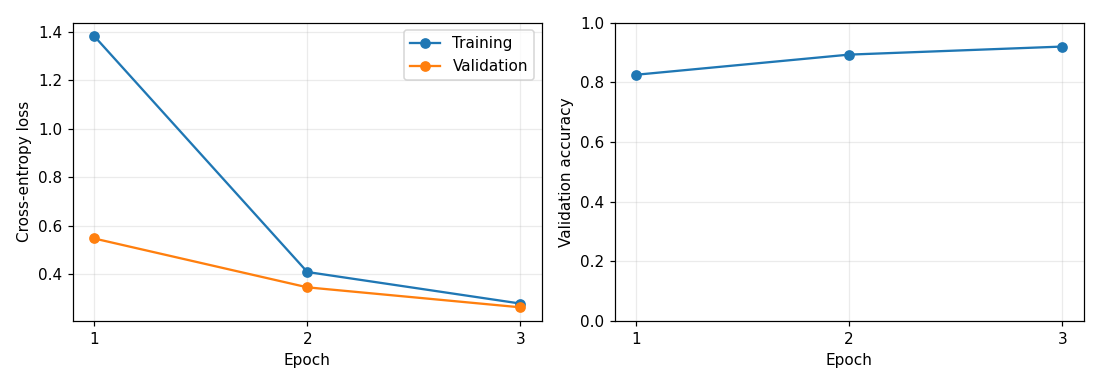

In [12]:
# Supplied: restart the baseline from the same initialisation before training.
torch.manual_seed(SEED)
model = make_model()
before_training = evaluate_model(model, val_loader, device)
print("Before training:", before_training)
history = train_model(
    model, train_loader, val_loader, criterion=criterion, device=device,
    epochs=EPOCHS, learning_rate=LEARNING_RATE, seed=SEED,
)
after_training = evaluate_model(model, val_loader, device)
print("After training:", after_training)
plot_history(history)


**Reference answer.**

The predictions are 2 and 7; only the first matches its true label, so accuracy is $1/2$. If all ten scores are zero, every class receives probability $1/10$ and the loss is $\log 10$. For the two rows in the example, the correct-label probabilities are
$e^3/(8+e+e^3)$ and $1/(9+e^2)$. Thus the mean cross-entropy is
$$
\frac{1}{2}\left[\log(8+e+e^3)-3+\log(9+e^2)\right].
$$
This differs from $\log 10$, because the rows do not have equal scores.

We expect training to lower the loss and improve validation accuracy, but neither is guaranteed at every epoch. The printed dictionaries provide the actual before/after values. One epoch only means one pass through the training data. The training loss averages changing parameters within an epoch, while validation loss uses the final parameters of that epoch; a lower validation loss is therefore not inherently suspicious. These are empirical observations, not a guarantee about all future images.


**Results in the saved CPU run.** The two-row example has mean loss about
1.6121 and accuracy 50%. The network's validation loss changes from 2.3024
before training to 0.2625 afterward; validation accuracy rises from 9.70% to
91.95%. The plotted loss decreases over the three epochs, while validation
accuracy increases. These are results of this particular run, not required
values for your own implementation. One epoch does not guarantee perfect
recognition: after three epochs there are still validation mistakes.


## 4. Evaluate and inspect predictions · Tutorial, 20 minutes

**(a)** Write `predict_labels(model, batch_images, device)`: given one batch of images, return a **CPU tensor** containing one predicted integer label per image. Put the model on `device` and in evaluation mode, use `torch.no_grad()`, move the images to the same device, and choose the largest score in each row.

**(b)** Write `accuracy_on_loader(model, loader, device)`, returning a Python float. Loop over the batches, use your prediction function, count correct predictions and all images, then divide the totals:

$$
\operatorname{accuracy}=\frac{1}{n}\sum_{i=1}^{n}
   \mathbf{1}\{\widehat y_i=y_i\}.
$$

Do not average batch accuracies equally: the final batch may be smaller. Compute validation accuracy and check it against the supplied evaluator. The test set remains reserved for Exercise 5.

**(c)** Write code that selects and displays correct predictions and mistakes from the validation set. Discuss up to two mistakes, if any occur. If there are none in the first batch, search the complete validation set. Handle the case of no mistakes without failing.

**Useful tools:** `model.to(device)`, `model.eval()`, `with torch.no_grad():`, `.to(device)`, `.cpu()`, `.argmax(dim=1)`, `.sum().item()`, and Boolean indexing. Evaluation mode changes the behaviour of layers such as dropout; it does not itself disable gradient recording.


**Programming hints.** Start with the prediction function, test it on `images[:3]`, and only then write the accuracy loop. A function returns its result with `return`. Use two counters, initially zero, and add the number of correct labels and the current batch length at each step.

This tiny example illustrates comparison and selection without solving the evaluation loop:

```python
guesses = torch.tensor([2, 7, 4])
targets = torch.tensor([2, 1, 4])
mask = guesses == targets
print(mask.sum().item())   # Number of matches.
print(guesses[~mask])      # Select the entries where mask is false.
```

The loader gives CPU labels. Returning CPU predictions lets you compare them directly. For the image gallery, collect one prediction tensor per batch in a list, then join the list with `torch.cat`. Use the resulting Boolean masks to select matching images, labels, and predictions together.


**4(a): one prediction per image.** The model and images must be on the same
device (CPU or GPU). `model.eval()` selects evaluation behaviour for layers
such as dropout; it does not switch off gradient recording. The indented
block under `with torch.no_grad():` does that separately. We only need the
scores here, not derivatives. Finally, `.cpu()` returns labels on the CPU so
we can compare them with the dataset labels. These operations do not train
the model or update its parameters.


In [13]:
def predict_labels(model, batch_images, device):
    model.to(device)
    model.eval()
    with torch.no_grad():
        batch_scores = model(batch_images.to(device))
        return batch_scores.argmax(dim=1).cpu()


In [14]:
# Supplied small interface check.
check_labels = predict_labels(model, images[:3], device)
assert check_labels.shape == (3,) and check_labels.device.type == "cpu"
assert check_labels.dtype == torch.int64
print("Three predicted labels:", check_labels.tolist())


Three predicted labels: [8, 0, 8]


**4(b): accumulate counts across batches.** Start two counters at zero.
For every batch, count correct predictions and add the batch size. `+=` means
"add to the current value". Return the ratio after the loop has finished.

For example, if a batch of 4 images has 3 correct predictions and a final
batch of 1 image has none, the accuracy is $3/5$, not the unweighted average
$(3/4+0)/2$. Every image must receive the same weight.


In [15]:
def accuracy_on_loader(model, loader, device):
    correct, total = 0, 0
    for batch_images, batch_labels in loader:
        predictions = predict_labels(model, batch_images, device)
        correct += (predictions == batch_labels.cpu()).sum().item()
        total += len(batch_labels)
    if total == 0:
        raise ValueError("Cannot measure accuracy on an empty dataset.")
    return correct / total


In [16]:
# Supplied check on held-out validation data, not the test set.
validation_accuracy = accuracy_on_loader(model, val_loader, device)
reference_accuracy = evaluate_model(model, val_loader, device)["accuracy"]
print(f"Your validation accuracy: {validation_accuracy:.2%}")
assert abs(validation_accuracy - reference_accuracy) < 1e-10


Your validation accuracy: 91.95%


In [17]:
# Supplied: collect the small validation set for inspection on the CPU.
image_batches, label_batches = [], []
for batch_images, batch_labels in val_loader:
    image_batches.append(batch_images)
    label_batches.append(batch_labels)
validation_images = torch.cat(image_batches)
validation_labels = torch.cat(label_batches)


**4(c): select correct predictions and mistakes.** A Python list collects
one prediction tensor per batch; `.append(...)` adds an item to it.
`torch.cat` joins the batches along their existing first dimension.
The validation loader does not shuffle, so this order matches the images
collected in the preceding cell.

`correct_mask` contains one Boolean value per image. Indexing with it selects
only the correct predictions; `~correct_mask` reverses the Booleans and selects
mistakes. Applying the same mask to images, labels, and predictions keeps them
aligned. `.any()` checks whether at least one mistake exists.


Correct predictions: 1839
Mistakes: 161


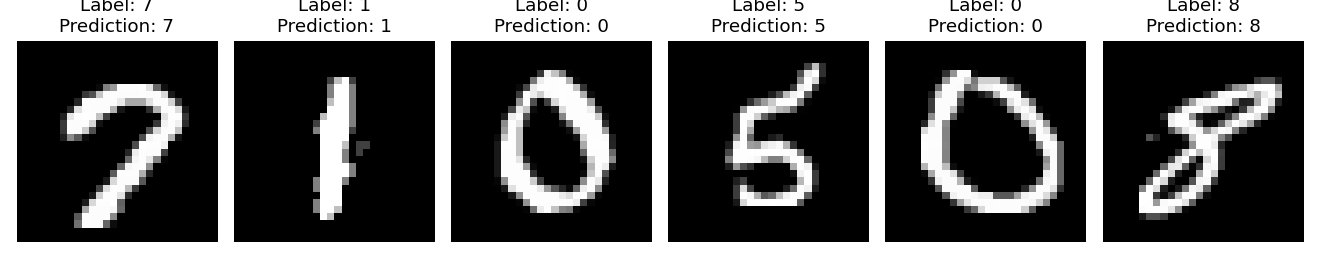

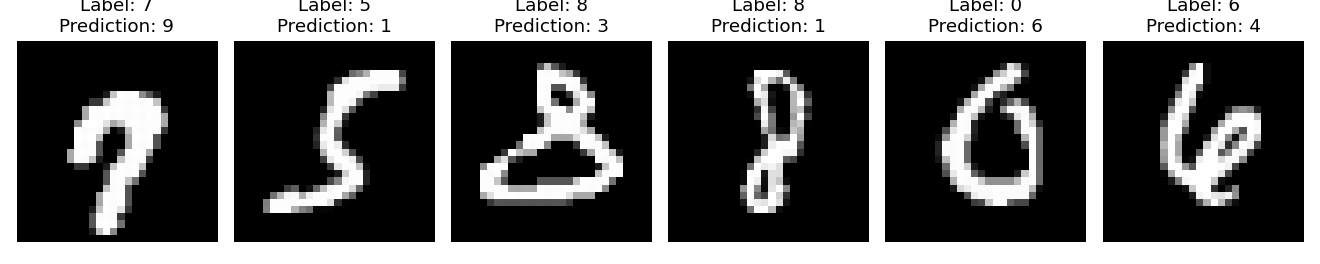

In [18]:
prediction_batches = []
for batch_images, batch_labels in val_loader:
    prediction_batches.append(predict_labels(model, batch_images, device))
validation_predictions = torch.cat(prediction_batches)
correct_mask = validation_predictions == validation_labels
mistake_mask = ~correct_mask
print("Correct predictions:", correct_mask.sum().item())
show_images(validation_images[correct_mask], labels=validation_labels[correct_mask],
            predictions=validation_predictions[correct_mask], max_images=6)
print("Mistakes:", mistake_mask.sum().item())
if mistake_mask.any():
    show_images(validation_images[mistake_mask], labels=validation_labels[mistake_mask],
                predictions=validation_predictions[mistake_mask], max_images=6)
else:
    print("No mistakes in this validation set.")


**Reference answer.**

The two accuracy calculations should agree. Counting all correct predictions and dividing by all images gives every image equal weight, including those in a smaller final batch. `eval()` selects evaluation behaviour; `no_grad()` prevents gradient recording during this calculation. Neither changes the parameters by training.

Inspect the actual displayed mistakes: incomplete strokes, ambiguous shapes, or an unusual writing style may help explain particular failures, but a visual explanation is a hypothesis. A high average accuracy allows individual errors. Validation data can guide our architecture choice; using test data for that choice would undermine its role as a final held-out evaluation.


**Examples in the saved run.** There are 1,839 correct predictions out of
2,000 validation images, hence accuracy 91.95%, with 161 mistakes.

- The first displayed mistake has true label 7 and prediction 9. Its thick,
  curved upper stroke and downward stroke could resemble a 9; this is a
  possible visual explanation, not evidence of what features the network used.
- The second has true label 5 and prediction 1. Its narrow shape and long
  middle stroke could contribute to the confusion, although its top and lower
  curves remain visible. Again, this interpretation is a hypothesis.

The actual mismatches are certain from the labels and predictions. Their
causes cannot be established from these pictures alone. A different run may
show different mistakes; describe the examples your own model produces.


## 6. Recognise new digits · Tutorial, 10 minutes

Use the first model trained in Exercise 3 for every experiment here. No homework code is needed. These few examples do not estimate accuracy on a population of new drawings.

**(a)** The supplied code draws three simple **synthetic, handwritten-style**
digits: 0, 1, and 7. These are not taken from MNIST. Inspect the images, predict
which might be difficult, and obtain the model's labels.

**(b)** Modify one of these images: move the digit a little, erase a stroke, or
change its brightness. State your expected effect before making the change,
then compare the predictions. A wrong prediction is a useful result to explain.
Do not assume that convolution and pooling guarantee exact translation invariance.

**Optional own image.** Draw one dark digit on a plain light background and save
a tightly framed PNG or JPEG beside this notebook, for example `my_digit.png`.
An image editor is sufficient; a camera is not required. `load_digit(path,
invert=True)` converts it to grayscale, inverts dark-on-light writing, crops
around the foreground, fits the digit into a $20\times20$ region, and centres
it on a dark $28\times28$ canvas. Inspect this prepared image before interpreting
the prediction. Use `invert=False` for a light digit on a dark background.
This simple preparation does not correct arbitrary shadows or complicated backgrounds.


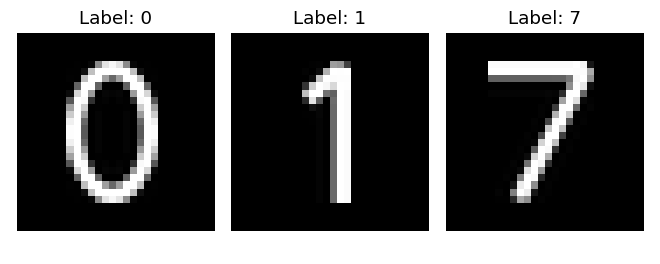

In [19]:
# Supplied: examples are generated locally, with no additional download.
new_images = make_example_digits()
intended_labels = torch.tensor([0, 1, 7])
show_images(new_images, labels=intended_labels, max_images=3)

experiment_model = model  # The tutorial model trained in Exercise 3.


**Example expectation for 6(a).** These drawings have simple shapes, but
their stroke thickness and centring may differ from MNIST. In particular, a
straight 1 or an unfamiliar 7 may be confused with another digit. We inspect
the predictions rather than assuming that all three will be recognised.


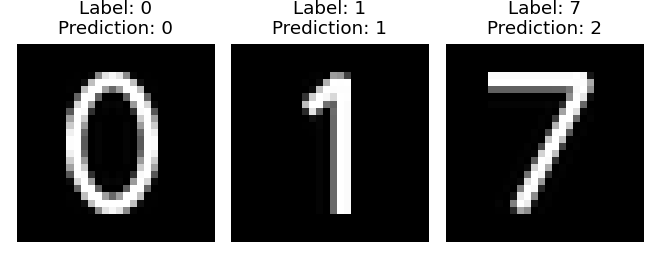

In [20]:
new_predictions = predict_labels(experiment_model, new_images, device)
show_images(new_images, labels=intended_labels, predictions=new_predictions, max_images=3)


**Hint for (b):** start from `new_images.clone()`. To change brightness,
multiply an image by a factor between 0 and 1. To erase a patch, use the
indexing from Exercise 1. Keep the resulting values in `[0, 1]`.


**Example expectation for 6(b).** We erase a central 6-by-6 patch of the
synthetic 7. This could interrupt its diagonal stroke and change the prediction;
the remaining strokes may still be enough. The slice `2:3` retains the batch
dimension, so both the original and modified inputs have shape `(1, 1, 28, 28)`.
`torch.cat` then joins them into a batch of two images.


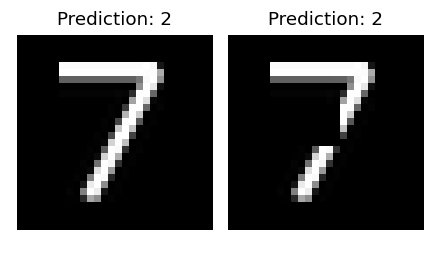

In [21]:
chosen_index = 2
original_new = new_images[chosen_index:chosen_index + 1]
changed_digit = original_new.clone()
changed_digit[:, :, 10:16, 10:16] = 0.0
comparison = torch.cat([original_new, changed_digit])
comparison_predictions = predict_labels(experiment_model, comparison, device)
show_images(comparison, predictions=comparison_predictions, max_images=2)


### Optional: draw your own digit here

Set `enable_drawing_pad = True` in the following cell and run it, then draw **one digit from 0 to 9** with your mouse or
touchscreen. Click **Recognise** to see the model's prediction and the actual
$28\times28$ image presented to the network. Click **Clear** and try another digit.
You do not need to write any drawing or JavaScript code.

The pad uses the tutorial model trained in Exercise 3. Run the training
cells first. These few drawings are an informal experiment, not an accuracy estimate.

The drawing pad is **optional**. If `anywidget` is missing, run
`%pip install "anywidget>=0.9.18,<1"` in a new notebook cell on MIN, local Python,
or Colab. For the `AnyModel` error on MIN, save your notebooks and use
**File → Hub Control Panel → Stop My Server → Start My Server**, then reopen
JupyterLab and hard-refresh the browser. A kernel restart alone may not load
the extension. The troubleshooting section near the start of this notebook
gives the complete steps for each setup route. Rerun your model and training
cells after a restart, then try the pad again. If it still fails, use the
image-file option below and send the error to your tutor.

**Save a drawing as ordinary notebook output:** after clicking Recognise, run
the **Record drawing** cell below. This preserves the prepared image and its
prediction when you save the notebook; the interactive pad alone may not survive
a kernel restart or a downloaded copy.


In [22]:
# Supplied optional drawing pad. Rerunning this cell replaces the previous pad.
previous_pad = globals().get("drawing_pad")
if previous_pad is not None:
    previous_pad.close()
drawing_pad = None

enable_drawing_pad = False  # Change to True to try the optional live widget.
if enable_drawing_pad:
    try:
        # Colab needs its custom-widget manager; other environments skip this step.
        try:
            from google.colab import output
            output.enable_custom_widget_manager()
        except ImportError:
            pass
        from IPython.display import display
        from lab_02_support import digit_drawer

        drawing_model = experiment_model
        drawing_pad = digit_drawer(drawing_model, device)
        display(drawing_pad)
    except ImportError as error:
        print("The optional drawing pad is unavailable:", error)
        print('MIN, local Python, or Colab: run %pip install "anywidget>=0.9.18,<1" '
              'in a separate cell, then follow the restart steps near the notebook start.')
        print("MIN: save all notebooks, then File > Hub Control Panel > Stop My Server > "
              "Start My Server; reopen and refresh JupyterLab.")
        print("Nix: re-enter the supplied environment instead of using pip.")
        print("After restarting, rerun the model and training cells before trying the pad.")
        print("You can still use the supplied digits or load an image file below.")
else:
    print("Optional pad disabled. Set enable_drawing_pad = True to draw a digit.")


Optional pad disabled. Set enable_drawing_pad = True to draw a digit.


In [23]:
# Supplied: run AFTER clicking Recognise to save an ordinary image output.
if (drawing_pad is not None and drawing_pad.last_image is not None
        and drawing_pad.last_prediction is not None):
    show_images(drawing_pad.last_image.unsqueeze(0),
                predictions=[drawing_pad.last_prediction], max_images=1)
else:
    print("Draw a digit, click Recognise, then run this cell again.")
    print("If the pad is unavailable, continue with the other image examples.")


Draw a digit, click Recognise, then run this cell again.
If the pad is unavailable, continue with the other image examples.


### Optional alternative: load an image file

You can use this option without the drawing pad. Save a single digit image
beside the notebook and set its filename below. The image preparation is
described at the beginning of Exercise 6.


In [24]:
# Supplied optional extension: change None to a filename only if you want to try it.
own_image_path = None  # For example: "my_digit.png"
if own_image_path is not None:
    own_image = load_digit(Path(own_image_path), invert=True)
    own_batch = own_image.unsqueeze(0)  # Add the batch dimension: (1, 1, 28, 28).
    image_model = experiment_model
    own_prediction = predict_labels(image_model, own_batch, device)
    show_images(own_batch, predictions=own_prediction, max_images=1)


**Reference answer.**

Read the predictions from the displayed output: success on these synthetic digits is not guaranteed. The chosen modification erases a central patch from the synthetic 7. It may leave enough visible structure for recognition, but a prediction change is also informative.

MNIST and our synthetic drawings differ in stroke shape, centring, thickness, and background. Convolution and pooling do not guarantee invariance to all translations or erased strokes. A few drawings cannot estimate population accuracy. If using the optional pad, record an actual recognised drawing with the supplied recording cell; the image-file route tests personal handwriting without any widget dependency.


**Results in the saved run.** The synthetic digits 0, 1, and 7 receive
predictions 0, 1, and 2 respectively. Thus the first two are recognised and the
7 is already misclassified before the modification. After the central patch
is removed from the 7, its prediction remains 2. In this example the change
does not alter the predicted label, but the label is still incorrect. The
remaining shape is recognisable to a human reader even though the model fails.


## Using this reference

The saved code and plots were checked on CPU with PyTorch 2.15.0+cpu and
torchvision 0.29.2+cpu. You do not need to install these exact versions; use
the compatible course environment. The optional drawing pad was not used
in the saved run. Enable it only if you want to try a live drawing.

Work through the explanations, compare them with your own attempt, and keep
your answers in your chosen exercise notebook. Homework remains in that
notebook; this reference covers only tutorial Exercises 1–4 and 6.
